# 15 — Can relative-price features improve longer-history LightGBM?

**Optional research after a completed 09b direct-history search.** Select the same verified Python 3.12 project kernel, then **Restart Kernel and Run All**. No earlier notebooks are executed and no downloads are made. Keep the verified 2024 cache and prepared run.

**One question:** do seven simple percentage-based momentum/variation features improve AP beyond the completed longer-history Optuna control? The model settings, training rows, evaluation rows, 10% labels and coverage rules stay fixed. This isolates a feature change; there is **no extra hyperparameter search**.

Protocol: verify the control → rebuild its exact longer-history training → fit enhanced features on each of three expanding folds → freeze the fold conclusion → evaluate January–March 2026 once → save a separate research result. **0.70 AP is an aspirational reference, not a stopping rule, guaranteed result or deployment requirement.** Report lower scores as well as gains. Already-inspected folds/validation remain exploratory; no April–June test or registered November outcome is read.

The dashboard and main model-comparison workflow remain unchanged. This notebook does not correct suspicious prices, redefine surges or establish future accuracy. Each execution saves a timestamped study inside the active run's `research/15_relative_price_features/`.

## 1. Verify the completed longer-history control

Use `optuna` from the latest completed 09b run, not whichever model happens to have the largest validation score. Restore matching inputs if verification fails; do not remove a hash guard. The saved settings are fixed before any new fit.

In [1]:
import sys
from pathlib import Path
REPOSITORY_ROOT = Path.cwd().resolve()
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    raise FileNotFoundError("Open this notebook inside the FYP repository.")
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

import ast
import hashlib
import json
from datetime import datetime, timezone
from importlib import metadata, reload
from time import perf_counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             precision_score, recall_score, f1_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from lightgbm import LGBMClassifier
import pricecatcher_config as cfg
cfg = reload(cfg)

def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

history_runs = sorted((cfg.PROJECT_ROOT / "09b_longer_history_lightgbm").glob("*/tuned/study_manifest.json"), reverse=True)
if not history_runs:
    raise FileNotFoundError("Complete 09b_longer_history_lightgbm.ipynb first.")
control_dir = history_runs[0].parent.parent / "optuna"
if not (control_dir / "study_manifest.json").is_file():
    raise FileNotFoundError("The latest 09b run needs its completed direct-history Optuna result.")
parent = cfg.verify_saved_study(control_dir)
selection = parent["selection"]
if selection["family"] != "LightGBM" or selection["training_start"] != "2024-01":
    raise ValueError("Expected the completed longer-history LightGBM control.")
if sys.version_info[:2] != tuple(map(int, parent["python_version"].split(".")[:2])):
    raise ValueError("Use the same Python major/minor version as 09b.")
for package in ["lightgbm", "scikit-learn", "numpy", "pandas", "joblib"]:
    if metadata.version(package) != parent["package_versions"][package]:
        raise ValueError(f"Use the saved 09b {package} version for this controlled comparison.")

FOLDS = ["fold_1", "fold_2", "fold_3"]
folders = {name: cfg.PROJECT_ROOT / "experiments" / name / "05_modelling" for name in FOLDS + ["holdout"]}
settings_by_fold = {name: json.loads((folder / "experiment_settings.json").read_text()) for name, folder in folders.items()}
settings = settings_by_fold["holdout"]
if any(settings["preparation"][key] != value for key, value in cfg.PREPARATION_SETTINGS.items()):
    raise ValueError("Current configuration differs from the saved preparation. Restore its matching configuration.")
FEATURES, NUMERIC, CATEGORICAL = (settings[key] for key in ["feature_columns", "numeric_features", "categorical_features"])
if FEATURES != selection["feature_columns"] or settings["surge_threshold_pct"] != 10:
    raise ValueError("Keep the control feature list and 10% definition unchanged.")
MODEL_PARAMETERS = {**selection["fixed_parameters"], **selection["parameters"],
                    "random_state": selection["seed"], "n_jobs": selection["n_jobs"]}
control_model = joblib.load(control_dir / "lightgbm.joblib")
fitted_parameters = control_model.named_steps["model"].get_params()
if any(fitted_parameters[key] != value for key, value in MODEL_PARAMETERS.items()):
    raise ValueError("Declared model settings differ from the saved control model.")
parent_manifest_sha256 = file_hash(control_dir / "study_manifest.json")
configuration_sha256 = file_hash(Path(cfg.__file__))
print("Active run:", cfg.PROJECT_ROOT)
print("Frozen control:", control_dir)
print("Parameters (unchanged):", MODEL_PARAMETERS)

Active run: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240
Frozen control: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/09b_longer_history_lightgbm/20261028_180021_892503/optuna
Parameters (unchanged): {'colsample_bytree': 0.8, 'max_depth': -1, 'objective': 'binary', 'verbosity': -1, 'learning_rate': 0.06485076026339508, 'n_estimators': 400, 'num_leaves': 31, 'min_child_samples': 20, 'reg_lambda': 8.439801017111947, 'class_weight': None, 'random_state': 42, 'n_jobs': 2}


## 2. Add seven readable, past/current-only ratios

| New feature | Calculation | Interpretation |
|---|---|---|
| `change_2w_pct`, `change_4w_pct` | 100 × (current / exact-week lag − 1) | Medium-term momentum |
| `deviation_4w_pct`, `deviation_8w_pct` | 100 × (current / past rolling mean − 1) | Current price relative to its recent level |
| `variation_4w_pct`, `variation_8w_pct` | 100 × past rolling standard deviation / past rolling mean | Variation relative to price level |
| `within_week_variation_pct` | 100 × current within-week standard deviation / current median | Current observed price dispersion |

These scale-free ratios may help share patterns across items with different price levels. Trees already see the underlying inputs, so a gain is **not guaranteed**. No new economic drivers are added. Missing denominators/lags stay missing until training-fitted imputation. Ratios are not clipped or used to exclude rows. No future fields enter features.

In [2]:
EXTRA_FEATURES = ["change_2w_pct", "change_4w_pct", "deviation_4w_pct", "deviation_8w_pct",
                  "variation_4w_pct", "variation_8w_pct", "within_week_variation_pct"]
FORMULAS = {
    "change_2w_pct": "100 * (weekly_median_price / lag_2w_price - 1)",
    "change_4w_pct": "100 * (weekly_median_price / lag_4w_price - 1)",
    "deviation_4w_pct": "100 * (weekly_median_price / rolling_mean_4w - 1)",
    "deviation_8w_pct": "100 * (weekly_median_price / rolling_mean_8w - 1)",
    "variation_4w_pct": "100 * rolling_std_4w / rolling_mean_4w",
    "variation_8w_pct": "100 * rolling_std_8w / rolling_mean_8w",
    "within_week_variation_pct": "100 * weekly_std_price / weekly_median_price",
}

def model_inputs(frame, enhanced=False):
    X = frame[FEATURES].copy()
    if enhanced:
        price = X.weekly_median_price
        for lag in [2, 4]:
            denominator = X[f"lag_{lag}w_price"].where(X[f"lag_{lag}w_price"] > 0)
            X[f"change_{lag}w_pct"] = 100 * (price / denominator - 1)
        for window in [4, 8]:
            mean = X[f"rolling_mean_{window}w"].where(X[f"rolling_mean_{window}w"] > 0)
            X[f"deviation_{window}w_pct"] = 100 * (price / mean - 1)
            X[f"variation_{window}w_pct"] = 100 * X[f"rolling_std_{window}w"] / mean
        X["within_week_variation_pct"] = 100 * X.weekly_std_price / price.where(price > 0)
        if np.isinf(X[EXTRA_FEATURES].to_numpy(dtype=float)).any():
            raise ValueError("Infinite derived features; inspect the retained source prices.")
    for column in CATEGORICAL:
        X[column] = X[column].astype("string").fillna("__missing__").astype(str)
    return X

def fit_enhanced(training, evaluation):
    preprocess = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True), NUMERIC + EXTRA_FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL),
    ], sparse_threshold=1.0)
    model = Pipeline([("preprocess", preprocess), ("model", LGBMClassifier(**MODEL_PARAMETERS))])
    model.fit(model_inputs(training, enhanced=True), training.surge_label.astype(int))
    scores = model.predict_proba(model_inputs(evaluation, enhanced=True))[:, 1]
    if not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError("Expected finite model scores in [0, 1].")
    return model, scores

def evaluate(y, scores, cutoff):
    y = np.asarray(y, dtype=int)
    alerts = np.asarray(scores) >= cutoff
    tn, fp, fn, tp = confusion_matrix(y, alerts, labels=[0, 1]).ravel()
    return {"rows": len(y), "positives": int(y.sum()), "average_precision":
        float(average_precision_score(y, scores)) if len(np.unique(y)) == 2 else np.nan,
        "cutoff": cutoff, "precision": precision_score(y, alerts, zero_division=0),
        "recall": recall_score(y, alerts, zero_division=0) if y.sum() else np.nan,
        "f1": f1_score(y, alerts, zero_division=0) if y.sum() else np.nan,
        "alerts": int(alerts.sum()), "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}

## 3. Reuse 09b's verified training reconstruction

To avoid a second version of the historical-cleaning/weekly-label code, load **only the two named function definitions** from 09b. No notebook cells, downloads, tuning or deployment code are executed. As in 09b, original 2025 features/labels are reconstructed and checked before 2024 is added. The rebuilt counts must match this control's recorded populations.

The source functions, configuration and this notebook's calculation code are fingerprinted in the research manifest. The model inputs remain derived exclusively from the saved preparation and historical cache.

In [3]:
history_notebook = REPOSITORY_ROOT / "09b_longer_history_lightgbm.ipynb"
source_nb = json.loads(history_notebook.read_text())
functions = []
for cell in source_nb["cells"]:
    if cell["cell_type"] == "code":
        tree = ast.parse("".join(cell["source"]))
        functions.extend(node for node in tree.body if isinstance(node, ast.FunctionDef)
                         and node.name in {"training_table", "prepare_training"})
if sorted(node.name for node in functions) != ["prepare_training", "training_table"]:
    raise ValueError("09b training helpers changed; review compatibility before this study.")
calculation = ast.Module(body=functions, type_ignores=[])
helper_sha256 = hashlib.sha256(ast.dump(calculation).encode()).hexdigest()
exec(compile(calculation, str(history_notebook), "exec"), globals())
helper_notebook_sha256 = file_hash(history_notebook)

additional_inputs = parent["additional_input_sha256"]
historical_paths = [cfg.resolve_input(path) for path in additional_inputs
                    if cfg.resolve_input(path).name == "selected_prices_2024.parquet"]
if len(historical_paths) != 1:
    raise ValueError("Expected the exact 2024 source snapshot recorded by 09b.")
earlier_source = pd.read_parquet(historical_paths[0], columns=cfg.GROUP_KEYS + ["date", "premise_code", "price"])
earlier_source["date"] = pd.to_datetime(earlier_source.date)
if earlier_source.empty or not earlier_source.date.between("2024-01-01", "2024-12-31").all():
    raise ValueError("Supplementary source must contain only the recorded 2024 observations.")
features, keys = FEATURES, cfg.GROUP_KEYS + ["week_start"]
training_rows, cleaning_rows = [], []
expected_support = pd.read_csv(control_dir / "training_comparison.csv")

def matching_training(name):
    training, evaluation = prepare_training(name)
    for history, recorded in [("2025-only", training_rows[-2]), ("2024-added", training_rows[-1])]:
        expected = expected_support.loc[expected_support.fold.eq(name) & expected_support.history.eq(history)]
        if len(expected) != 1:
            raise ValueError(f"{name}: missing original support evidence.")
        for column in ["rows", "positives", "first_week", "last_outcome"]:
            if str(recorded[column]) != str(expected.iloc[0][column]):
                raise ValueError(f"{name}: rebuilt {history} {column} differs from 09b.")
    if training.surge_label.nunique() != 2 or evaluation.surge_label.nunique() != 2:
        raise ValueError("Both classes are needed for the overall AP comparison.")
    return training, evaluation

## 4. Compare the three folds before opening later validation

Fit once per fold using the seven additional features and the exact frozen control settings. Reuse the control's verified fold metrics. Report the unweighted mean AP difference and all three fold differences; a positive mean does not prove statistical significance. No seeds/settings/feature subsets are tried until a preferred result appears.

In [4]:
control_folds = pd.read_csv(control_dir / "fold_comparison.csv")
control_folds = control_folds.loc[control_folds.method.eq(selection["comparison_method"])].copy()
if len(control_folds) != 3 or set(control_folds.fold) != set(FOLDS):
    raise ValueError("Expected exactly three recorded control folds.")
control_summary = pd.read_csv(control_dir / "fold_summary.csv").set_index("method").loc[selection["comparison_method"]]
np.testing.assert_allclose([control_summary.mean_ap, control_summary.std_ap],
    [control_folds.average_precision.mean(), control_folds.average_precision.std()], rtol=1e-10, atol=1e-12)
fold_rows = []
for name in FOLDS:
    training, evaluation = matching_training(name)
    started = perf_counter()
    model, scores = fit_enhanced(training, evaluation)
    original = control_folds.set_index("fold").loc[name]
    if int(original.rows) != len(evaluation) or int(original.positives) != int(evaluation.surge_label.sum()):
        raise ValueError("Control and enhanced fold evaluation populations differ.")
    fold_rows.append({"fold": name, "training_rows": len(training), "evaluation_rows": len(evaluation),
        "control_ap": float(original.average_precision),
        "enhanced_ap": float(average_precision_score(evaluation.surge_label, scores)),
        "fit_and_score_seconds": perf_counter() - started})
    del training, evaluation, model, scores

fold_comparison = pd.DataFrame(fold_rows)
fold_comparison["ap_change"] = fold_comparison.enhanced_ap - fold_comparison.control_ap
fold_summary = pd.DataFrame([
    {"method": "Frozen 09b Optuna control", "features": len(FEATURES),
     "mean_fold_ap": fold_comparison.control_ap.mean(), "std_fold_ap": fold_comparison.control_ap.std()},
    {"method": "Add relative-price features", "features": len(FEATURES) + len(EXTRA_FEATURES),
     "mean_fold_ap": fold_comparison.enhanced_ap.mean(), "std_fold_ap": fold_comparison.enhanced_ap.std()},
])
fold_gain = float(fold_comparison.ap_change.mean())
fold_conclusion = "Higher mean fold AP" if fold_gain > 0 else "No improvement in mean fold AP"
display(fold_comparison)
display(fold_summary)
print(fold_conclusion, "| difference:", round(fold_gain, 6))
print("Fold conclusion frozen before Jan–Mar validation; this is exploratory evidence.")

,fold,training_rows,evaluation_rows,control_ap,enhanced_ap,fit_and_score_seconds,ap_change
0,fold_1,266477,31971,0.377467,0.357891,4.860253,-0.019576
1,fold_2,301608,31753,0.397623,0.393634,5.507823,-0.003989
2,fold_3,338389,54666,0.535816,0.539271,6.160411,0.003455


,method,features,mean_fold_ap,std_fold_ap
0,Frozen 09b Optuna control,22,0.436969,0.086195
1,Add relative-price features,29,0.430265,0.096078


No improvement in mean fold AP | difference: -0.006704
Fold conclusion frozen before Jan–Mar validation; this is exploratory evidence.


## 5. Evaluate January–March once, even if the folds declined

Use the saved control model and scores after verifying the matching identifiers and labels. Its fresh predictions must reproduce the saved scores. Only now rebuild holdout training and fit the enhanced model. The enhanced cutoff maximises validation F1 (highest cutoff breaks ties), exactly as 09b; these are apparent cutoff-selection metrics, not independent test results.

Report both models at the common 0.5 reference and their own selected cutoffs. Also report group counts so an aggregate gain cannot hide scarce positives. The fixed 10% event definition is unchanged. Reaching 0.70 only on folds does not establish 0.70 later-period performance.

In [5]:
training, validation = matching_training("holdout")
prediction_keys = ["item_code", "state", "district", "premise_type", "project_group",
                   "week_start", "next_week_end", "surge_label"]
identifiers = prediction_keys[:-1]
validation = validation.sort_values(identifiers).reset_index(drop=True)
control_predictions = pd.read_parquet(control_dir / "validation_predictions.parquet").sort_values(identifiers).reset_index(drop=True)
if validation.duplicated(identifiers).any() or control_predictions.duplicated(identifiers).any():
    raise ValueError("Duplicate evaluation identifiers.")
pd.testing.assert_frame_equal(validation[prediction_keys], control_predictions[prediction_keys])
control_scores = control_model.predict_proba(model_inputs(validation))[:, 1]
np.testing.assert_allclose(control_scores, control_predictions.model_score, rtol=1e-9, atol=1e-11)
enhanced_model, enhanced_scores = fit_enhanced(training, validation)
del training, control_model

p, r, cutoffs = precision_recall_curve(validation.surge_label, enhanced_scores)
f1 = np.divide(2*p[:-1]*r[:-1], p[:-1]+r[:-1], out=np.zeros(len(cutoffs)), where=(p[:-1]+r[:-1]) > 0)
enhanced_cutoff = float(cutoffs[np.flatnonzero(np.isclose(f1, f1.max(), rtol=0, atol=1e-12))[-1]])
score_sets = {"Frozen 09b Optuna control": (control_scores, float(selection["score_cutoff"])),
              "Add relative-price features": (enhanced_scores, enhanced_cutoff)}
validation_rows, group_rows = [], []
predictions = validation[prediction_keys].copy()
for method, (scores, cutoff) in score_sets.items():
    for role, threshold in [("common 0.5 reference", 0.5), ("apparent cutoff-selection performance", cutoff)]:
        validation_rows.append({"method": method, "role": role, **evaluate(validation.surge_label, scores, threshold)})
    for group, positions in validation.groupby("project_group", sort=True).indices.items():
        group_rows.append({"method": method, "project_group": group,
                           **evaluate(validation.iloc[positions].surge_label, scores[positions], cutoff)})
    prefix = "control" if method.startswith("Frozen") else "enhanced"
    predictions[prefix + "_score"] = scores
    predictions[prefix + "_alert"] = scores >= cutoff
validation_comparison = pd.DataFrame(validation_rows)
validation_groups = pd.DataFrame(group_rows)
display(validation_comparison)
display(validation_groups)
validation_gain = float(average_precision_score(validation.surge_label, enhanced_scores)
                        - average_precision_score(validation.surge_label, control_scores))
print("Later validation AP difference:", round(validation_gain, 6))
print("0.70 reached on mean folds:", bool(fold_comparison.enhanced_ap.mean() >= 0.70))
print("0.70 reached on later validation:", bool(average_precision_score(validation.surge_label, enhanced_scores) >= 0.70))
print("Neither period is an independent final test; no dashboard replacement is made.")

,method,role,rows,positives,average_precision,cutoff,precision,recall,f1,alerts,tp,fp,fn,tn
0,Frozen 09b Optuna control,common 0.5 reference,43594,3912,0.317784,0.500000,0.414550,0.183538,0.254429,1732,718,1014,3194,38668
1,Frozen 09b Optuna control,apparent cutoff-selection performance,43594,3912,0.317784,0.218639,0.280959,0.524284,0.365858,7300,2051,5249,1861,34433
2,Add relative-price features,common 0.5 reference,43594,3912,0.301656,0.500000,0.385147,0.171012,0.236856,1737,669,1068,3243,38614
3,Add relative-price features,apparent cutoff-selection performance,43594,3912,0.301656,0.183460,0.268996,0.574642,0.366452,8357,2248,6109,1664,33573


,method,project_group,rows,positives,average_precision,cutoff,precision,recall,f1,alerts,tp,fp,fn,tn
0,Frozen 09b Optuna control,Chicken,4884,25,0.364238,0.218639,0.388889,0.280000,0.325581,18,7,11,18,4848
1,Frozen 09b Optuna control,Cooking Oil,2178,1,0.000493,0.218639,0.000000,0.000000,0.000000,0,0,0,1,2177
2,Frozen 09b Optuna control,Eggs,8892,53,0.091180,0.218639,0.125000,0.056604,0.077922,24,3,21,50,8818
3,Frozen 09b Optuna control,Flour,1110,15,0.245503,0.218639,0.200000,0.066667,0.100000,5,1,4,14,1091
4,Frozen 09b Optuna control,Rice,384,2,0.833333,0.218639,0.000000,0.000000,0.000000,0,0,0,2,382
5,Frozen 09b Optuna control,Sugar,1837,0,NaN,0.218639,0.000000,NaN,NaN,0,0,0,0,1837
6,Frozen 09b Optuna control,Vegetables,24309,3816,0.320920,0.218639,0.281263,0.534591,0.368597,7253,2040,5213,1776,15280
7,Add relative-price features,Chicken,4884,25,0.219020,0.183460,0.243902,0.400000,0.303030,41,10,31,15,4828
8,Add relative-price features,Cooking Oil,2178,1,0.000512,0.183460,0.000000,0.000000,0.000000,0,0,0,1,2177
9,Add relative-price features,Eggs,8892,53,0.091596,0.183460,0.152174,0.132075,0.141414,46,7,39,46,8800


Later validation AP difference: -0.016128
0.70 reached on mean folds: False
0.70 reached on later validation: False
Neither period is an independent final test; no dashboard replacement is made.


## 6. Save the complete research evidence

The model, formulas, row support, fold/validation/group metrics, scores, protocol and plot live together in one new study folder. A completed manifest is written last. No pointer, earlier experiment or source file is rewritten. Keep this research candidate separate from Notebook 10 and dashboard deployment.

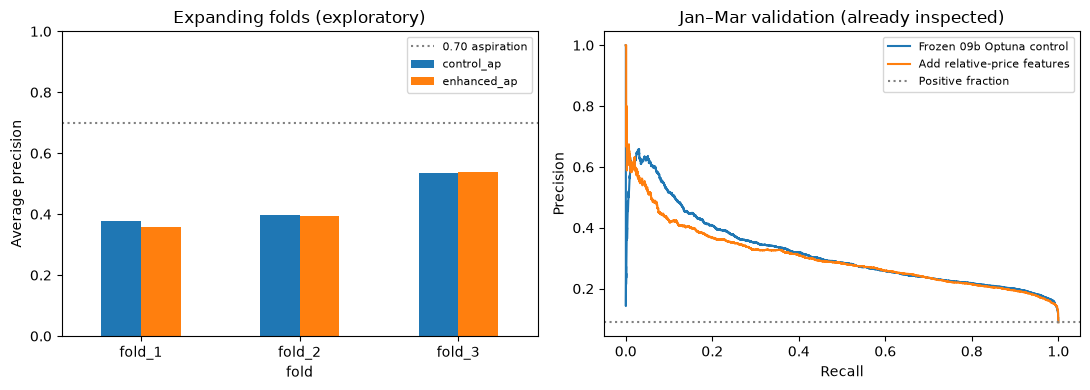

Saved: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/research/15_relative_price_features/20261103_050022_128295
Share fold_summary.csv, validation_comparison.csv and validation_group_metrics.csv for interpretation.


In [6]:
# Verify upstream bytes again before publishing a completed study.
cfg.verify_saved_study(control_dir)
if (file_hash(control_dir / "study_manifest.json") != parent_manifest_sha256
        or file_hash(history_notebook) != helper_notebook_sha256
        or file_hash(Path(cfg.__file__)) != configuration_sha256):
    raise ValueError("Parent study or calculation code changed during this experiment.")
this_notebook = REPOSITORY_ROOT / "research" / "15_relative_price_features.ipynb"
notebook = json.loads(this_notebook.read_text())
code_sha256 = hashlib.sha256("\n".join("".join(c["source"]) for c in notebook["cells"]
                                       if c["cell_type"] == "code").encode()).hexdigest()
output = cfg.PROJECT_ROOT / "research" / "15_relative_price_features" / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
output.mkdir(parents=True, exist_ok=False)
for name, table in {"fold_comparison.csv": fold_comparison, "fold_summary.csv": fold_summary,
    "validation_comparison.csv": validation_comparison, "validation_group_metrics.csv": validation_groups,
    "training_support.csv": pd.DataFrame(training_rows), "historical_cleaning.csv": pd.DataFrame(cleaning_rows)}.items():
    table.to_csv(output / name, index=False)
predictions.to_parquet(output / "validation_predictions.parquet", index=False)
joblib.dump(enhanced_model, output / "research_model.joblib")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fold_comparison.set_index("fold")[["control_ap", "enhanced_ap"]].plot.bar(ax=axes[0], rot=0)
for method, (scores, _) in score_sets.items():
    precision, recall, _ = precision_recall_curve(validation.surge_label, scores)
    axes[1].plot(recall, precision, label=method)
axes[0].axhline(0.70, color="grey", linestyle=":", label="0.70 aspiration")
axes[0].set(ylabel="Average precision", ylim=(0, 1), title="Expanding folds (exploratory)")
axes[1].axhline(validation.surge_label.mean(), color="grey", linestyle=":", label="Positive fraction")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Jan–Mar validation (already inspected)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(output / "comparison.png", dpi=150); plt.show()
protocol = {"status": "completed", "question": "seven relative-price features with fixed longer-history LightGBM settings",
    "python_version": sys.version.split()[0], "parameters": MODEL_PARAMETERS,
    "feature_columns": FEATURES + EXTRA_FEATURES, "extra_feature_formulas": FORMULAS,
    "surge_threshold_pct": 10.0, "fold_conclusion": fold_conclusion,
    "mean_fold_ap_change": fold_gain, "validation_ap_change": validation_gain,
    "score_cutoff": enhanced_cutoff, "score_interpretation": "uncalibrated model score",
    "aspirational_ap": 0.70, "independent_test_evaluated": False, "dashboard_changed": False,
    "selection_rule": "fixed feature experiment; fold conclusion before later validation; no hyperparameter search",
    "validation_role": "already-inspected exploratory comparison and F1 cutoff selection",
    "parent_study": cfg.input_reference(control_dir / "study_manifest.json"),
    "parent_manifest_sha256": parent_manifest_sha256,
    "input_sha256": parent["input_sha256"], "additional_input_sha256": parent["additional_input_sha256"],
    "historical_helper_sha256": helper_sha256, "configuration_sha256": configuration_sha256,
    "research_code_sha256": code_sha256,
    "package_versions": {p: metadata.version(p) for p in ["lightgbm", "scikit-learn", "numpy", "pandas", "joblib"]},
    "output_sha256": {p.name: file_hash(p) for p in output.iterdir()}}
(output / "research_manifest.json").write_text(json.dumps(protocol, indent=2))
print("Saved:", output)
print("Share fold_summary.csv, validation_comparison.csv and validation_group_metrics.csv for interpretation.")

## 7. How to interpret the result

- **Both periods improve:** a promising exploratory feature experiment, requiring genuinely independent confirmation. Do not call it established future accuracy.
- **Folds improve but later validation falls:** the additional representation did not generalise consistently; retain that negative result rather than tuning against validation.
- **Neither improves:** the existing model may already recover these ratios adequately, or they may add little predictive information. Do not increase trials just to chase 0.70.
- **AP rises but precision/F1 declines:** ranking and the chosen alert operating point answer different questions. Compare counts and group support before discussing usefulness.

This experiment cannot establish that the data are error-free, that 0.70 is achievable, or that affordability improves. A change to labels, populations, source corrections or external drivers would be another separately justified study. Do not restart the main pipeline, delete `data/`, or change a dashboard pin to run this notebook.